In [8]:

# =====================================================
# PARTE 3 - SALVAR RESULTADOS DA COMPARAÇÃO
# =====================================================

from pathlib import Path

# Localizar a pasta da Parte 3
pasta_parte3 = raiz / "parte 3"

# Garantir que a pasta existe
pasta_parte3.mkdir(parents=True, exist_ok=True)

# Caminho do arquivo de resultados
arquivo_comparacao = pasta_parte3 / "comparacao_modelos.csv"

# Salvar os resultados calculados no notebook
comparacao.to_csv(
    arquivo_comparacao,
    index=False,
    encoding="utf-8-sig"
)

print("RESULTADOS SALVOS COM SUCESSO!")
print("-" * 45)
print(f"Arquivo: {arquivo_comparacao}")
print(f"Modelos comparados: {len(comparacao)}")

display(comparacao)


RESULTADOS SALVOS COM SUCESSO!
---------------------------------------------
Arquivo: c:\Users\felipe.sfreitas5\Downloads\ICD-Desigualdade-Genero\parte 3\comparacao_modelos.csv
Modelos comparados: 2


,Modelo,MAE (R$),R²
0,Random Forest,2082.098742,0.170474
1,Ridge Regression,2110.716733,0.155169


COMPARAÇÃO DOS MODELOS
---------------------------------------------


,Modelo,MAE (R$),R²
0,Random Forest,"R$ 2,082.10",0.1705
1,Ridge Regression,"R$ 2,110.72",0.1552


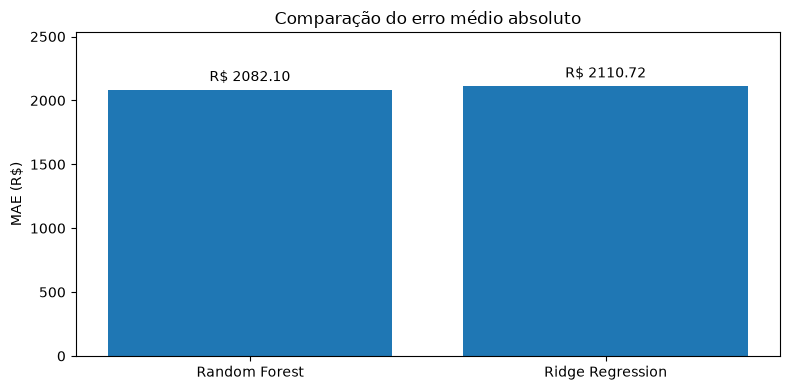

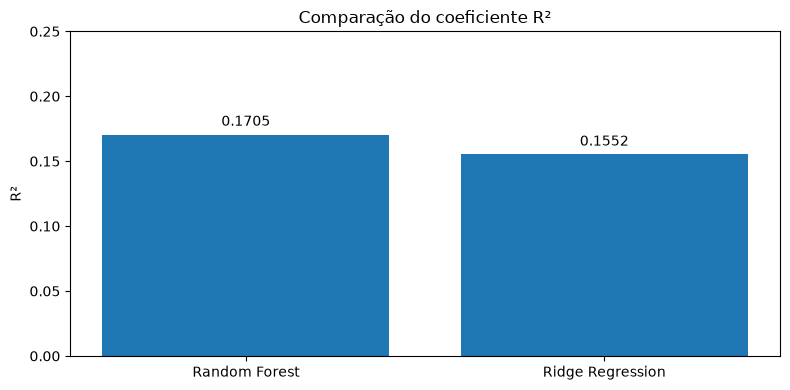


Melhor modelo pelo MAE: Random Forest
Diferença entre os erros médios: R$ 28.62


In [7]:

# =====================================================
# PARTE 3 - COMPARAÇÃO DOS MODELOS
# =====================================================

import pandas as pd
import matplotlib.pyplot as plt

# Construir tabela de comparação
comparacao = pd.DataFrame({
    "Modelo": [
        "Random Forest",
        "Ridge Regression"
    ],
    "MAE (R$)": [
        mae_rf,
        mae_ridge
    ],
    "R²": [
        r2_rf,
        r2_ridge
    ]
})

print("COMPARAÇÃO DOS MODELOS")
print("-" * 45)

display(
    comparacao.style.format({
        "MAE (R$)": "R$ {:,.2f}",
        "R²": "{:.4f}"
    })
)

# Gráfico 1 - Erro médio absoluto
fig, ax = plt.subplots(figsize=(8, 4))

barras = ax.bar(
    comparacao["Modelo"],
    comparacao["MAE (R$)"]
)

ax.bar_label(
    barras,
    fmt="R$ %.2f",
    padding=4
)

ax.set_title("Comparação do erro médio absoluto")
ax.set_ylabel("MAE (R$)")
ax.set_ylim(0, comparacao["MAE (R$)"].max() * 1.2)

plt.tight_layout()
plt.show()

# Gráfico 2 - Coeficiente R²
fig, ax = plt.subplots(figsize=(8, 4))

barras = ax.bar(
    comparacao["Modelo"],
    comparacao["R²"]
)

ax.bar_label(
    barras,
    fmt="%.4f",
    padding=4
)

ax.set_title("Comparação do coeficiente R²")
ax.set_ylabel("R²")
ax.set_ylim(0, max(0.25, comparacao["R²"].max() * 1.2))

plt.tight_layout()
plt.show()

# Identificar o melhor modelo pelo MAE
melhor_modelo = comparacao.loc[
    comparacao["MAE (R$)"].idxmin(),
    "Modelo"
]

diferenca_mae = abs(mae_rf - mae_ridge)

print(f"\nMelhor modelo pelo MAE: {melhor_modelo}")
print(f"Diferença entre os erros médios: R$ {diferenca_mae:.2f}")


In [6]:

# =====================================================
# MODELO 2 - RIDGE REGRESSION
# =====================================================

from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler

# Pré-processamento específico para o Ridge
preprocessamento_ridge = ColumnTransformer(
    transformers=[
        (
            "categoricas",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categoricas
        ),
        (
            "idade",
            StandardScaler(),
            numericas
        )
    ]
)

# Pipeline de regressão Ridge
modelo_ridge = Pipeline(
    steps=[
        ("preprocessamento", preprocessamento_ridge),
        ("regressor", Ridge(alpha=10.0))
    ]
)

# Treinamento com pesos amostrais
modelo_ridge.fit(
    X_treino,
    y_treino_log,
    regressor__sample_weight=peso_treino.to_numpy()
)

# Previsões para o conjunto de teste
previsoes_ridge_log = modelo_ridge.predict(X_teste)

# Conversão das previsões para reais
previsoes_ridge = np.expm1(previsoes_ridge_log)
previsoes_ridge = np.clip(previsoes_ridge, 0, None)

# Avaliação ponderada
mae_ridge = mean_absolute_error(
    y_teste,
    previsoes_ridge,
    sample_weight=peso_teste
)

r2_ridge = r2_score(
    y_teste,
    previsoes_ridge,
    sample_weight=peso_teste
)

print("MODELO RIDGE TREINADO COM SUCESSO!")
print("-" * 45)
print(f"Erro médio absoluto (MAE): R$ {mae_ridge:,.2f}")
print(f"Coeficiente R²: {r2_ridge:.4f}")
print(f"Quantidade de registros de teste: {len(X_teste):,}")


MODELO RIDGE TREINADO COM SUCESSO!
---------------------------------------------
Erro médio absoluto (MAE): R$ 2,110.72
Coeficiente R²: 0.1552
Quantidade de registros de teste: 4,886



## Interpretação dos resultados

Foram treinados e avaliados dois modelos de regressão supervisionada: Random Forest Regressor e Ridge Regression.

O **Random Forest apresentou o melhor desempenho**, com MAE de R$ 2.082,10 e R² de 0,1705.

O Ridge Regression apresentou MAE de R$ 2.110,72 e R² de 0,1552.

A diferença de R$ 28,62 entre os erros médios absolutos favorece o Random Forest, embora seja relativamente pequena.

Os resultados indicam que as variáveis gênero, idade, escolaridade e setor econômico fornecem informações úteis para estimar rendimentos, mas não são suficientes para explicar grande parte da variação observada.

**Limitações identificadas:**

- O estudo utiliza dados de apenas um trimestre da PNAD Contínua.
- A modelagem considera somente quatro características explicativas.
- Fatores como experiência profissional, jornada de trabalho e ocupação detalhada não foram incluídos.
- As diferenças de rendimento não comprovam relações causais ou discriminação salarial isoladamente.

Como continuidade, seria possível testar outras variáveis, ajustar os hiperparâmetros dos modelos e avaliar seu desempenho em outros períodos.

**Conclusão:** entre os modelos avaliados, o Random Forest apresentou os melhores resultados, mas ambos devem ser utilizados com cautela em aplicações de apoio à decisão.


In [5]:

# =====================================================
# MODELO 1 - RANDOM FOREST REGRESSOR
# =====================================================

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

# Variáveis categóricas e numéricas
categoricas = ["Genero", "Escolaridade", "Setor"]
numericas = ["Idade"]

# Transformação das variáveis
preprocessamento_rf = ColumnTransformer(
    transformers=[
        (
            "categoricas",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categoricas
        ),
        (
            "numericas",
            "passthrough",
            numericas
        )
    ]
)

# Pipeline do modelo
modelo_rf = Pipeline(
    steps=[
        ("preprocessamento", preprocessamento_rf),
        (
            "regressor",
            RandomForestRegressor(
                n_estimators=80,
                max_depth=12,
                min_samples_leaf=25,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

# Treinar o modelo usando o logaritmo do rendimento
modelo_rf.fit(
    X_treino,
    y_treino_log,
    regressor__sample_weight=peso_treino.to_numpy()
)

# Fazer previsões com os dados de teste
previsoes_rf_log = modelo_rf.predict(X_teste)

# Converter as previsões para reais
previsoes_rf = np.expm1(previsoes_rf_log)
previsoes_rf = np.clip(previsoes_rf, 0, None)

# Calcular métricas ponderadas
mae_rf = mean_absolute_error(
    y_teste,
    previsoes_rf,
    sample_weight=peso_teste
)

r2_rf = r2_score(
    y_teste,
    previsoes_rf,
    sample_weight=peso_teste
)

print("MODELO RANDOM FOREST TREINADO COM SUCESSO!")
print("-" * 45)
print(f"Erro médio absoluto (MAE): R$ {mae_rf:,.2f}")
print(f"Coeficiente R²: {r2_rf:.4f}")
print(f"Quantidade de registros de teste: {len(X_teste):,}")


MODELO RANDOM FOREST TREINADO COM SUCESSO!
---------------------------------------------
Erro médio absoluto (MAE): R$ 2,082.10
Coeficiente R²: 0.1705
Quantidade de registros de teste: 4,886



## Comparação dos modelos preditivos

Os modelos Random Forest e Ridge foram treinados e avaliados com os mesmos registros da PNAD Contínua.

A comparação considera duas métricas:

- **MAE (Erro Médio Absoluto):** representa a diferença absoluta média entre os rendimentos reais e previstos. Quanto menor, melhor.
- **R² (Coeficiente de Determinação):** avalia o desempenho preditivo em relação à referência baseada na média do conjunto de teste. Quanto maior, melhor.

A comparação permitirá identificar qual modelo apresentou melhor desempenho na estimativa de rendimentos.

Os resultados não devem ser interpretados como evidência de causalidade entre gênero e salário.


In [4]:

# =====================================================
# PARTE 3 - DIVISÃO EM TREINAMENTO E TESTE
# =====================================================

from sklearn.model_selection import train_test_split
import numpy as np

# Divisão reproduzível e estratificada por gênero
X_treino, X_teste, y_treino, y_teste, peso_treino, peso_teste = (
    train_test_split(
        X,
        y,
        pesos,
        test_size=0.25,
        random_state=42,
        stratify=X["Genero"]
    )
)

# Transformação logarítmica do rendimento
# para manter a metodologia da Parte 2
y_treino_log = np.log1p(y_treino)

print("DIVISÃO DOS DADOS CONCLUÍDA")
print("-" * 45)

print(f"Registros para treinamento: {len(X_treino):,}")
print(f"Registros para teste: {len(X_teste):,}")

print("\nDistribuição de gênero no treinamento:")
display(X_treino["Genero"].value_counts())

print("\nDistribuição de gênero no teste:")
display(X_teste["Genero"].value_counts())


DIVISÃO DOS DADOS CONCLUÍDA
---------------------------------------------
Registros para treinamento: 14,657
Registros para teste: 4,886

Distribuição de gênero no treinamento:


Genero
Homens      8070
Mulheres    6587
Name: count, dtype: int64


Distribuição de gênero no teste:


Genero
Homens      2690
Mulheres    2196
Name: count, dtype: int64


## Modelo 2 — Ridge Regression

O Ridge é um algoritmo de regressão linear com regularização L2, utilizado para estimar valores numéricos.

**Justificativa da escolha:** comparar um modelo linear regularizado com o Random Forest, que consegue representar relações não lineares.

Para realizar uma comparação justa, utilizaremos os mesmos registros de treinamento e teste, a mesma variável-alvo, os mesmos pesos amostrais e a mesma transformação logarítmica do rendimento.

As variáveis categóricas serão transformadas com One-Hot Encoding, enquanto a idade será padronizada com StandardScaler.

A avaliação será realizada com MAE e R², calculados sobre os rendimentos convertidos novamente para reais.


In [3]:

# =====================================================
# PARTE 3 - PREPARAÇÃO DOS DADOS PARA MODELAGEM
# =====================================================

# Criar uma cópia para preservar os dados originais
df_modelo = dados.copy()

# Variáveis explicativas e variável-alvo
variaveis = [
    "Genero",
    "Idade",
    "Escolaridade",
    "Setor"
]

alvo = "Rendimento"

# Garantir que as colunas numéricas tenham o tipo correto
for coluna in ["Ocupado", "Rendimento", "Peso", "Idade"]:
    df_modelo[coluna] = pd.to_numeric(
        df_modelo[coluna],
        errors="coerce"
    )

# Selecionar pessoas ocupadas com informações válidas
df_modelo = df_modelo[
    (df_modelo["Ocupado"] == 1)
    & (df_modelo["Rendimento"] > 0)
    & (df_modelo["Peso"] > 0)
    & (df_modelo["Idade"] >= 14)
    & (df_modelo["Idade"] <= 110)
    & df_modelo[variaveis].notna().all(axis=1)
].copy()

# Organizar índices
df_modelo = df_modelo.reset_index(drop=True)

# Separar variáveis de entrada, alvo e pesos
X = df_modelo[variaveis]
y = df_modelo[alvo]
pesos = df_modelo["Peso"]

print("PREPARAÇÃO DOS DADOS CONCLUÍDA")
print("-" * 45)
print(f"Registros originais: {len(dados):,}")
print(f"Registros válidos para modelagem: {len(df_modelo):,}")
print(f"Registros excluídos: {len(dados) - len(df_modelo):,}")
print(f"Variáveis explicativas: {variaveis}")
print(f"Variável-alvo: {alvo}")

display(df_modelo[variaveis + [alvo, "Peso"]].head())


PREPARAÇÃO DOS DADOS CONCLUÍDA
---------------------------------------------
Registros originais: 38,483
Registros válidos para modelagem: 19,543
Registros excluídos: 18,940
Variáveis explicativas: ['Genero', 'Idade', 'Escolaridade', 'Setor']
Variável-alvo: Rendimento


,Genero,Idade,Escolaridade,Setor,Rendimento,Peso
0,Mulheres,55,Superior completo,"Educação, saúde e serviços sociais",6000.0,1708.074158
1,Homens,21,Superior completo,"Informação, comunicação, finanças e serviços p...",2500.0,1708.074158
2,Mulheres,42,Superior completo,"Educação, saúde e serviços sociais",2500.0,1161.462400
3,Mulheres,45,Médio completo,Outros serviços,2500.0,1577.317593
4,Mulheres,35,Médio completo,"Informação, comunicação, finanças e serviços p...",2000.0,1314.155680



## Modelo 1 — Random Forest Regressor

O Random Forest é um algoritmo de aprendizado supervisionado utilizado para tarefas de regressão e classificação.

Neste projeto, ele será utilizado para estimar o rendimento mensal habitual dos trabalhadores.

**Justificativa da escolha:** o algoritmo consegue representar relações não lineares entre as características dos trabalhadores e seus rendimentos.

As variáveis categóricas serão convertidas em indicadores numéricos com One-Hot Encoding. A idade será mantida como variável numérica.

O modelo será treinado com pesos amostrais e com o logaritmo do rendimento, seguindo a metodologia já utilizada na Parte 2.


In [1]:
import pandas as pd
import numpy as np
import sklearn

print("Ambiente configurado com sucesso!")

Ambiente configurado com sucesso!


In [2]:

from pathlib import Path
import pandas as pd

# Localizar a raiz do projeto
pasta_atual = Path.cwd()

if (pasta_atual / "dados" / "dados_tratados.csv").exists():
    raiz = pasta_atual
elif (pasta_atual.parent / "dados" / "dados_tratados.csv").exists():
    raiz = pasta_atual.parent
else:
    raise FileNotFoundError(
        "Não foi possível localizar dados/dados_tratados.csv"
    )

caminho_dados = raiz / "dados" / "dados_tratados.csv"

# Carregar a base tratada da Parte 1
dados = pd.read_csv(caminho_dados)

print("Base carregada com sucesso!")
print(f"Quantidade de registros: {len(dados):,}")
print(f"Quantidade de colunas: {len(dados.columns)}")

print("\nColunas disponíveis:")
print(dados.columns.tolist())

# Visualizar os primeiros registros
display(dados.head())


Base carregada com sucesso!
Quantidade de registros: 38,483
Quantidade de colunas: 17

Colunas disponíveis:
['UF', 'V1028', 'V2007', 'V2009', 'VD3004', 'VD4002', 'VD4010', 'VD4016', 'VD4019', 'Genero', 'Idade', 'Escolaridade', 'Setor', 'Ocupado', 'Rendimento', 'Peso', 'Faixa_Etaria']


,UF,V1028,V2007,V2009,VD3004,VD4002,VD4010,VD4016,VD4019,Genero,Idade,Escolaridade,Setor,Ocupado,Rendimento,Peso,Faixa_Etaria
0,35,1708.074158,1,60,7.0,2.0,NaN,NaN,NaN,Homens,60,Superior completo,NaN,0.0,NaN,1708.074158,55 a 64
1,35,1708.074158,2,55,7.0,1.0,9.0,6000.0,6000.0,Mulheres,55,Superior completo,"Educação, saúde e serviços sociais",1.0,6000.0,1708.074158,55 a 64
2,35,1708.074158,1,21,7.0,1.0,7.0,2500.0,2500.0,Homens,21,Superior completo,"Informação, comunicação, finanças e serviços p...",1.0,2500.0,1708.074158,14 a 24
3,35,1161.462400,2,42,7.0,1.0,9.0,2500.0,2500.0,Mulheres,42,Superior completo,"Educação, saúde e serviços sociais",1.0,2500.0,1161.462400,35 a 44
4,35,1982.648057,2,24,5.0,2.0,NaN,NaN,NaN,Mulheres,24,Médio completo,NaN,0.0,NaN,1982.648057,14 a 24
